
# COMP8410 — Week 3: Identity Preservation and Controlled Image Editing


In [1]:
import os, sys, json, time, gc, subprocess, hashlib, re
from pathlib import Path
import importlib.metadata as md_
import numpy as np
import pandas as pd
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU runtime in Colab: Runtime > Change runtime type > GPU.")
print("GPU:", torch.cuda.get_device_name(0))
print(f"Total GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GiB")

device = torch.device("cuda:0")
WORK_DIR = Path("/content/comp8410_week3")
INPUT_DIR, OUTPUT_DIR = WORK_DIR / "inputs", WORK_DIR / "outputs"
MASK_DIR = WORK_DIR / "masks"
for p in (INPUT_DIR, OUTPUT_DIR, MASK_DIR):
    p.mkdir(parents=True, exist_ok=True)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
Total GPU memory: 39.49 GiB


In [17]:
%pip -q install --upgrade diffusers transformers accelerate safetensors sentencepiece
%pip -q install scikit-image scipy lpips pytesseract
!apt-get -qq update && apt-get -qq install -y tesseract-ocr > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
# ------------------------------- CONFIGURATION -------------------------------
SIZE = 1024                      
SEEDS = [42, 43, 44]             
STEPS = 28                       
WARMUP = True                    


FLUX_PROMPT = (
    "Change only the colour of the product tube (body and cap) to muted sage green. "
    "Preserve the exact tube silhouette, cap shape, proportions, printed text and its layout, "
    "lighting, shadows, camera angle, background and composition. "
    "Keep the result photorealistic as premium skincare product photography."
)

PA_SOURCE_PROMPT = "A dark olive green skincare tube with white text on a dusty pink beige background with a green clay smear."
PA_EDIT_PROMPT   = "A muted sage green skincare tube with white text on a dusty pink beige background with a green clay smear."
TAU, SHIFT = 60, 0               

TARGET_RGB = (156, 175, 136)     
KEYWORDS = ["REFINE", "SUNDAY", "PEOPLE", "VITAMIN", "AVOCADO", "SQUALENE", "KAOLIN", "VETIVER"]  


DEFAULT_BOX, DEFAULT_POINT = (0.17, 0.04, 0.72, 0.80), (0.445, 0.44)
PROMPTS_BY_IMAGE = {}            
MANUAL_MASKS = {}                

print("Seeds:", SEEDS, "| size:", SIZE)

Seeds: [42, 43, 44] | size: 1024


Saving Capture.JPG to Capture.JPG
Capture.JPG: 802x753 -> centre-cropped 753x753 -> 1024x1024


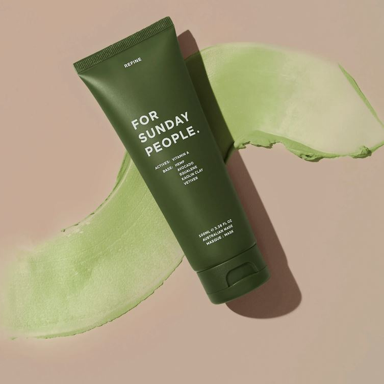

In [4]:
from google.colab import files
from PIL import Image
from IPython.display import display

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload at least one skincare or cosmetics product image.")

IMAGES, seen = {}, set()
for name, data in uploaded.items():
    digest = hashlib.md5(data).hexdigest()
    if digest in seen:
        print("Skipping duplicate upload:", name); continue
    seen.add(digest)
    stem = re.sub(r"[^A-Za-z0-9]+", "_", Path(name).stem).strip("_")
    (INPUT_DIR / Path(name).name).write_bytes(data)
    im = Image.open(INPUT_DIR / Path(name).name).convert("RGB")
    w, h = im.size
    s = min(w, h); left, top = (w - s) // 2, (h - s) // 2
    im = im.crop((left, top, left + s, top + s)).resize((SIZE, SIZE), Image.Resampling.LANCZOS)   # same input for every method
    im.save(INPUT_DIR / f"{stem}_input_{SIZE}.png")
    IMAGES[stem] = im
    print(f"{name}: {w}x{h} -> centre-cropped {s}x{s} -> {SIZE}x{SIZE}")
    display(im.resize((384, 384)))

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Capture: mask covers 15.5% of the image


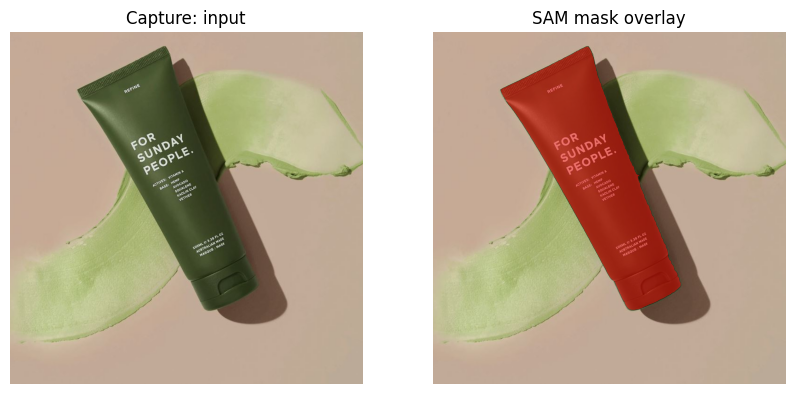

In [5]:
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from transformers import SamModel, SamProcessor

sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
sam = SamModel.from_pretrained("facebook/sam-vit-base").to(device).eval()

def segment(img, box, point):
    for use_point in (True, False):
        try:
            kw = dict(input_boxes=[[[float(v) for v in box]]])
            if use_point:
                kw.update(input_points=[[[[float(v) for v in point]]]], input_labels=[[[1]]])
            inputs = sam_proc(img, return_tensors="pt", **kw).to(device)
            with torch.no_grad():
                out = sam(**inputs, multimask_output=False)
            m = sam_proc.image_processor.post_process_masks(
                out.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]
            return m.reshape(-1, *m.shape[-2:])[0].numpy().astype(bool)
        except Exception as e:
            print("SAM prompt failed (use_point=%s): %s" % (use_point, e))
    raise RuntimeError("SAM failed; supply MANUAL_MASKS instead.")

def keep_largest(m):
    lab, n = ndi.label(m)
    if n <= 1:
        return m
    sizes = ndi.sum(m, lab, range(1, n + 1))
    return lab == (1 + int(np.argmax(sizes)))

TUBE_MASK, PA_MASK_FILES = {}, {}
for stem, img in IMAGES.items():
    if stem in MANUAL_MASKS:
        m = np.array(Image.open(MANUAL_MASKS[stem]).convert("L").resize((SIZE, SIZE), Image.NEAREST)) > 127
    else:
        p = PROMPTS_BY_IMAGE.get(stem, {})
        bx = [v * SIZE for v in p.get("box", DEFAULT_BOX)]
        pt = [v * SIZE for v in p.get("point", DEFAULT_POINT)]
        m = segment(img, bx, pt)
    m = keep_largest(ndi.binary_fill_holes(ndi.binary_closing(m, iterations=3)))
    frac = m.mean()
    print(f"{stem}: mask covers {frac:.1%} of the image")
    if not 0.03 <= frac <= 0.60:
        print("  WARNING: unusual mask size - check the overlay and adjust the SAM prompts or use MANUAL_MASKS")
    TUBE_MASK[stem] = m
    tube_dil = ndi.binary_dilation(m, iterations=6)          # small margin so edges are covered
    f_tube, f_bg = MASK_DIR / f"{stem}_mask_tube.png", MASK_DIR / f"{stem}_mask_background.png"
    Image.fromarray((tube_dil * 255).astype(np.uint8)).save(f_tube)       # white = preserved region (PA 'tube' mode)
    Image.fromarray((~tube_dil * 255).astype(np.uint8)).save(f_bg)        # white = preserved region (PA 'background' mode)
    PA_MASK_FILES[stem] = {"tube": f_tube, "background": f_bg}

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img); ax[0].set_title(f"{stem}: input"); ax[1].imshow(img)
    ax[1].imshow(np.ma.masked_where(~m, m), alpha=0.5, cmap="autumn"); ax[1].set_title("SAM mask overlay")
    for a in ax: a.axis("off")
    plt.show()

del sam, sam_proc
gc.collect(); torch.cuda.empty_cache()

In [6]:
from huggingface_hub import login
login()   # enter your token privately; never publish it in the notebook

from diffusers import FluxKontextPipeline

FLUX_ID = "black-forest-labs/FLUX.1-Kontext-dev"
flux_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
flux = FluxKontextPipeline.from_pretrained(FLUX_ID, torch_dtype=flux_dtype).to(device)
print("Loaded:", FLUX_ID, "| dtype:", flux_dtype)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded: black-forest-labs/FLUX.1-Kontext-dev | dtype: torch.bfloat16


In [ ]:
RUNS = []   

def run_flux(img, seed, steps=STEPS):
    g = torch.Generator(device="cuda").manual_seed(seed)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = flux(image=img, prompt=FLUX_PROMPT, guidance_scale=2.5, num_inference_steps=steps, generator=g).images[0]
    torch.cuda.synchronize()
    return out, time.perf_counter() - t0, torch.cuda.max_memory_allocated() / 1024**3

FLUX_NAME = "FLUX.1 Kontext Dev"
if WARMUP:
    first = next(iter(IMAGES.values()))
    run_flux(first, SEEDS[0], steps=4); print("Warm-up done (discarded).")

for stem, img in IMAGES.items():
    for seed in SEEDS:
        out, rt, mem = run_flux(img, seed)
        path = OUTPUT_DIR / f"{stem}_flux_seed{seed}.png"
        out.save(path)
        RUNS.append(dict(image=stem, method=FLUX_NAME, seed=seed, runtime_s=rt, peak_gpu_gib=mem, out_path=str(path), out_size=out.size))
        print(f"{stem} | {FLUX_NAME} | seed {seed}: {rt:.2f}s, {mem:.2f} GiB, output {out.size}")

del flux
gc.collect(); torch.cuda.empty_cache()

  0%|          | 0/4 [00:00<?, ?it/s]

Warm-up done (discarded).


  0%|          | 0/28 [00:00<?, ?it/s]

Capture | FLUX.1 Kontext Dev | seed 42: 27.05s, 33.83 GiB, output (1024, 1024)


  0%|          | 0/28 [00:00<?, ?it/s]

Capture | FLUX.1 Kontext Dev | seed 43: 27.11s, 33.83 GiB, output (1024, 1024)


  0%|          | 0/28 [00:00<?, ?it/s]

Capture | FLUX.1 Kontext Dev | seed 44: 27.15s, 33.83 GiB, output (1024, 1024)


In [8]:
REPO_URL = "https://github.com/fenghora/personalize-anything.git"
REPO_DIR = Path("/content/personalize-anything")
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
PA_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Personalize Anything commit:", PA_COMMIT)

sys.path.append(str(REPO_DIR))
from diffusers.models.attention_processor import FluxAttnProcessor2_0
from src.pipeline import RFInversionParallelFluxPipeline
from src.attn_processor import PersonalizeAnythingAttnProcessor, set_flux_transformer_attn_processor
from src.utils import create_mask, shift_tensor

Personalize Anything commit: 30e3b773a7723e525551bba65b77e49f7328b61b


In [9]:
PA_ID = "black-forest-labs/FLUX.1-dev"
pa = RFInversionParallelFluxPipeline.from_pretrained(PA_ID, torch_dtype=torch.float16, low_cpu_mem_usage=True).to(device)

latent_h = SIZE // (pa.vae_scale_factor * 2)
latent_w = SIZE // (pa.vae_scale_factor * 2)
img_dims = latent_h * latent_w

PA_VARIANTS = {
    "Personalize Anything (tube preserved)": "tube",             # the original configuration
    "Personalize Anything (background preserved)": "background",  # tube is regenerated from the edit prompt
}

def run_pa(img, mask_file, seed):
    mask_t = create_mask(str(mask_file), latent_w, latent_h)
    shift_mask = shift_tensor(mask_t, SHIFT)
    g = torch.Generator(device=device).manual_seed(seed)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    set_flux_transformer_attn_processor(pa.transformer, set_attn_proc_func=lambda name, dh, nh, ap: FluxAttnProcessor2_0())
    inv, lat, ids = pa.invert(source_prompt="", image=img, height=SIZE, width=SIZE, num_inversion_steps=STEPS, gamma=1.0)
    set_flux_transformer_attn_processor(
        pa.transformer,
        set_attn_proc_func=lambda name, dh, nh, ap: PersonalizeAnythingAttnProcessor(
            name=name, tau=TAU / 100, mask=mask_t, shift_mask=shift_mask, device=device, img_dims=img_dims))
    out = pa([PA_SOURCE_PROMPT, PA_EDIT_PROMPT], inverted_latents=inv, image_latents=lat, latent_image_ids=ids,
             height=SIZE, width=SIZE, start_timestep=0.0, stop_timestep=0.99,
             num_inference_steps=STEPS, eta=1.0, generator=g).images[1]
    torch.cuda.synchronize()
    return out, time.perf_counter() - t0, torch.cuda.max_memory_allocated() / 1024**3

if WARMUP:
    stem0 = next(iter(IMAGES))
    run_pa(IMAGES[stem0], PA_MASK_FILES[stem0]["tube"], SEEDS[0]); print("Warm-up done (discarded).")

for stem, img in IMAGES.items():
    for name, mode in PA_VARIANTS.items():
        slug = "pa_" + mode
        for seed in SEEDS:
            out, rt, mem = run_pa(img, PA_MASK_FILES[stem][mode], seed)
            path = OUTPUT_DIR / f"{stem}_{slug}_seed{seed}.png"
            out.save(path)
            RUNS.append(dict(image=stem, method=name, seed=seed, runtime_s=rt, peak_gpu_gib=mem, out_path=str(path), out_size=out.size))
            print(f"{stem} | {name} | seed {seed}: {rt:.2f}s, {mem:.2f} GiB")

del pa
gc.collect(); torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

... (21 outputs left out)

Capture | Personalize Anything (background preserved) | seed 43: 42.93s, 37.34 GiB


  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

Capture | Personalize Anything (background preserved) | seed 44: 42.95s, 37.34 GiB


In [10]:
import difflib, re
import numpy as np
from PIL import Image, ImageOps
from scipy import ndimage as ndi
from skimage.color import rgb2lab, rgb2gray, deltaE_ciede2000
from skimage.metrics import structural_similarity
from skimage.filters import threshold_otsu

def _lab(rgb):
    return rgb2lab(np.asarray(rgb, dtype=float).reshape(1, 1, 3) / 255.0)

def delta_e(rgb_a, rgb_b):
    return float(deltaE_ciede2000(_lab(rgb_a), _lab(rgb_b))[0, 0])

def median_colour(arr, mask):
    """Median RGB inside a mask (the median ignores the small share of white text pixels)."""
    return np.median(arr[mask], axis=0)

def ocr_scores(ref_arr, out_arr, mask, keywords=None):
    """Approximate packaging-text fidelity using OCR on the straightened tube region.
    Returns (text similarity to the original's OCR text, keyword recall, reference character count).
    OCR on small printed text is noisy: use these numbers for relative comparison only."""
    try:
        import pytesseract
        from skimage.filters import threshold_local
    except ImportError:
        return np.nan, np.nan, 0
    ys, xs = np.nonzero(mask)
    pts = np.stack([xs, ys], 1).astype(float)
    _, vecs = np.linalg.eigh(np.cov((pts - pts.mean(0)).T))
    ax, ay = vecs[:, 1]
    if ay < 0:
        ax, ay = -ax, -ay
    angle = float(np.degrees(np.arctan2(ax, ay)))   # tilt of the tube's long axis from vertical
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    keep = ndi.binary_erosion(mask, iterations=4)

    def read(arr):
        arr = arr.copy()
        body = np.median(arr[keep], axis=0).astype(np.uint8)
        arr[~keep] = body                                            # blank out everything outside the tube
        crop = Image.fromarray(arr[y0:y1, x0:x1].astype(np.uint8)).rotate(
            -angle, expand=True, resample=Image.BICUBIC, fillcolor=tuple(int(v) for v in body))
        g = crop.convert("L")
        a = np.array(g.resize((g.width * 2, g.height * 2), Image.LANCZOS))
        texts = []
        for binary in (a > threshold_local(a, 61, offset=-8), a > np.median(a) + 25):   # text is lighter than the body
            img = Image.fromarray(np.where(binary, 0, 255).astype(np.uint8))
            texts.append(re.sub(r"[^A-Z0-9]", "", pytesseract.image_to_string(img, config="--psm 6").upper()))
        return texts

    ref_t, out_t = read(ref_arr), read(out_arr)
    sim = difflib.SequenceMatcher(None, ref_t[0], out_t[0]).ratio() if ref_t[0] else np.nan
    recall = np.nan
    if keywords:
        joined = "".join(out_t)
        recall = sum(k.upper() in joined for k in keywords) / len(keywords)
    return sim, recall, len(ref_t[0])

def evaluate_edit(orig_img, out_img, tube_mask, target_rgb, lpips_fn=None, device="cpu", keywords=None):
    """Objective metrics for one edited image against the original. All images are PIL RGB, same size."""
    if out_img.size != orig_img.size:
        out_img = out_img.resize(orig_img.size, Image.LANCZOS)
    o, e = np.asarray(orig_img).astype(np.uint8), np.asarray(out_img).astype(np.uint8)
    inner = ndi.binary_erosion(tube_mask, iterations=10)          # tube interior, away from soft edges
    outer = ~ndi.binary_dilation(tube_mask, iterations=12)        # background, away from the tube
    col_o, col_e = median_colour(o, inner), median_colour(e, inner)
    res = {
        "tube_colour_rgb": tuple(int(round(v)) for v in col_e),
        "dE_to_target": delta_e(col_e, target_rgb),               # lower = closer to the requested sage green
        "dE_from_original": delta_e(col_e, col_o),                # how much the tube colour actually changed
    }
    g0, g1 = rgb2gray(o), rgb2gray(e)
    _, smap = structural_similarity(g0, g1, data_range=1.0, full=True)
    res["ssim_background"] = float(smap[outer].mean())            # higher = background preserved
    res["mae_background"] = float(np.abs(o.astype(float) - e.astype(float))[outer].mean())
    if lpips_fn is not None:
        import torch
        comp = np.where(ndi.binary_dilation(tube_mask, iterations=12)[..., None], o, e)   # compare background only
        t = lambda a: torch.from_numpy(a).permute(2, 0, 1)[None].float().div(127.5).sub(1).to(device)
        with torch.no_grad():
            res["lpips_background"] = float(lpips_fn(t(o), t(comp)).item())
    else:
        res["lpips_background"] = np.nan
    sim, recall, ref_len = ocr_scores(o, e, tube_mask, keywords)
    res["ocr_text_similarity"], res["ocr_keyword_recall"], res["ocr_ref_chars"] = sim, recall, ref_len
    return res


In [20]:
try:
    import lpips
    lpips_fn = lpips.LPIPS(net="alex").to(device).eval()
except Exception as e:
    print("LPIPS unavailable, skipping:", e); lpips_fn = None

# Sanity check: OCR on the original must recover most keywords, otherwise the OCR metrics are not meaningful
for stem, img in IMAGES.items():
    r = evaluate_edit(img, img, TUBE_MASK[stem], TARGET_RGB, lpips_fn, device, KEYWORDS)
    print(f"[sanity] {stem}: OCR keyword recall on the ORIGINAL = {r['ocr_keyword_recall']:.2f} "
          f"({r['ocr_ref_chars']} chars read)")

rows = []
for r in RUNS:
    orig = IMAGES[r["image"]]
    out = Image.open(r["out_path"]).convert("RGB")
    m = evaluate_edit(orig, out, TUBE_MASK[r["image"]], TARGET_RGB, lpips_fn, device, KEYWORDS)
    rows.append({**{k: v for k, v in r.items() if k != "out_size"}, "out_size": str(r["out_size"]), **m})
runs_df = pd.DataFrame(rows)
runs_df.to_csv(OUTPUT_DIR / "week3_runs.csv", index=False)
print(runs_df.round(3).to_string())

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
[sanity] Capture: OCR keyword recall on the ORIGINAL = 1.00 (133 chars read)
     image                                       method  seed  runtime_s  peak_gpu_gib                                                          out_path      out_size  tube_colour_rgb  dE_to_target  dE_from_original  ssim_background  mae_background  lpips_background  ocr_text_similarity  ocr_keyword_recall  ocr_ref_chars
0  Capture                           FLUX.1 Kontext Dev    42     27.052        33.831           /content/comp8410_week3/outputs/Capture_flux_seed42.png  (1024, 1024)  (149, 190, 165)         8.301            42.446            0.993           5.635             0.021                0.359               0.500            133
1  Capture                           FLUX.1 Kontext Dev    43     27.113        33.831           /content/comp8410_week3/outputs/Capture_flux_seed43.png  (1024, 1024)  (143, 185, 162)      

In [21]:
metric_cols = ["runtime_s", "peak_gpu_gib", "dE_to_target", "dE_from_original", "ssim_background",
               "lpips_background", "ocr_text_similarity", "ocr_keyword_recall"]
agg = runs_df.groupby("method")[metric_cols].agg(["mean", "std"]).round(3)
print(agg.to_string())
agg.to_csv(OUTPUT_DIR / "week3_summary_objective.csv")

                                            runtime_s        peak_gpu_gib      dE_to_target        dE_from_original        ssim_background        lpips_background        ocr_text_similarity        ocr_keyword_recall       
                                                 mean    std         mean  std         mean    std             mean    std            mean    std             mean    std                mean    std               mean    std
method                                                                                                                                                                                                                        
FLUX.1 Kontext Dev                             27.104  0.048       33.831  0.0        8.287  0.183           41.858  0.621           0.993  0.000            0.020  0.001               0.340  0.018              0.583  0.072
Personalize Anything (background preserved)    42.936  0.013       37.336  0.0        4.838  0.740          

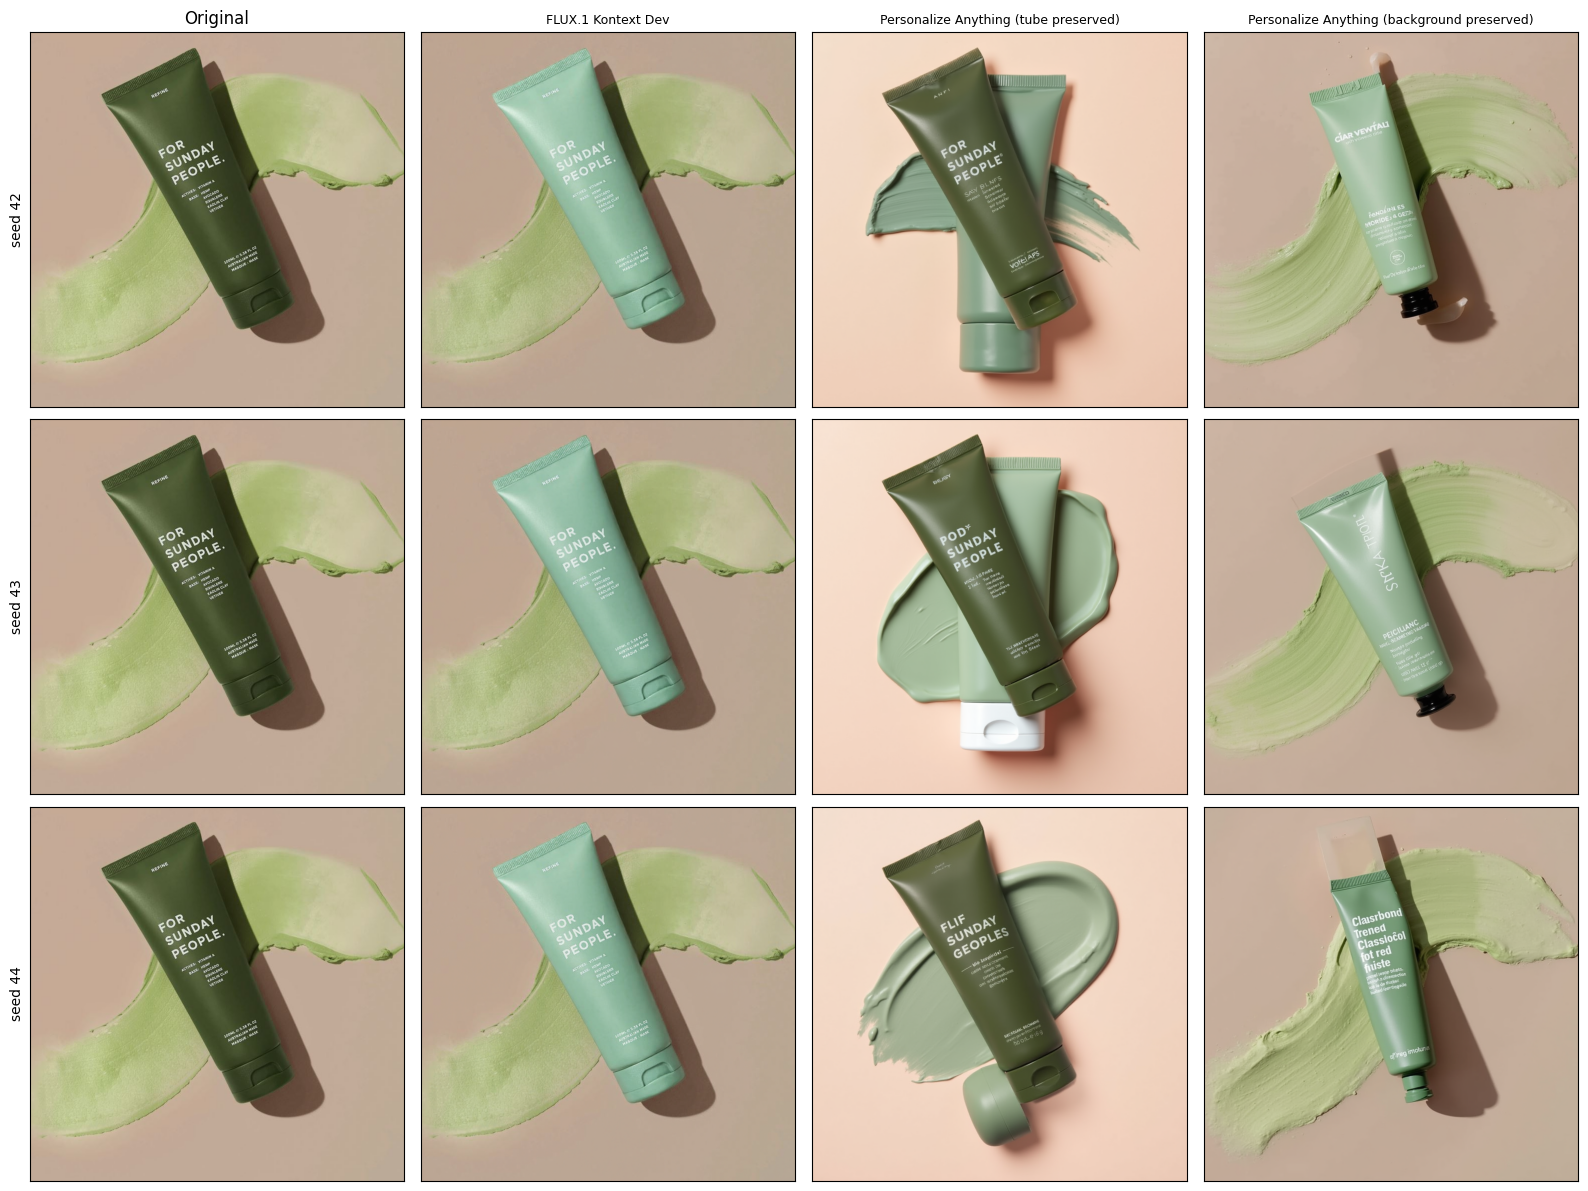

In [23]:
import matplotlib.pyplot as plt
methods = list(dict.fromkeys(r["method"] for r in RUNS))
for stem, img in IMAGES.items():
    fig, axes = plt.subplots(len(SEEDS), 1 + len(methods), figsize=(4 * (1 + len(methods)), 4 * len(SEEDS)), squeeze=False)
    for i, seed in enumerate(SEEDS):
        axes[i][0].imshow(img); axes[i][0].set_title("Original" if i == 0 else ""); axes[i][0].set_ylabel(f"seed {seed}")
        for j, meth in enumerate(methods, start=1):
            rec = next(r for r in RUNS if r["image"] == stem and r["method"] == meth and r["seed"] == seed)
            axes[i][j].imshow(Image.open(rec["out_path"]))
            if i == 0: axes[i][j].set_title(meth, fontsize=9)
        for a in axes[i]: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{stem}_comparison_grid.png", dpi=110)
    plt.show()

In [27]:
# EDIT THESE after inspecting the comparison grid. Keys must match the method names printed above.
MANUAL_RATINGS = {
    "FLUX.1 Kontext Dev": {
        "instruction_success": 3,
        "identity_preservation": 4,
        "composition_preservation": 4,
        "visual_quality": 5},
    "Personalize Anything (tube preserved)": {
        "instruction_success": 2,
        "identity_preservation": 3,
        "composition_preservation": 2,
        "visual_quality": 4
    },
    "Personalize Anything (background preserved)": {
        "instruction_success": 3,
        "identity_preservation": 1,
        "composition_preservation": 2,
        "visual_quality": 4
    }
}

summary = runs_df.groupby("method")[metric_cols].mean().round(3)
if MANUAL_RATINGS:
    summary = summary.join(pd.DataFrame(MANUAL_RATINGS).T)
else:
    print("No manual ratings entered yet - fill MANUAL_RATINGS and re-run this cell.")
print(summary.to_string())
summary.to_csv(OUTPUT_DIR / "week3_results.csv")

                                             runtime_s  peak_gpu_gib  dE_to_target  dE_from_original  ssim_background  lpips_background  ocr_text_similarity  ocr_keyword_recall  instruction_success  identity_preservation  composition_preservation  visual_quality
method                                                                                                                                                                                                                                                                
FLUX.1 Kontext Dev                              27.104        33.831         8.287            41.858            0.993             0.020                0.340               0.583                    3                      4                         4               5
Personalize Anything (background preserved)     42.936        37.336         4.838            38.685            0.916             0.143                0.133               0.000                    4              

In [28]:
pkgs = ["torch", "diffusers", "transformers", "accelerate", "scikit-image", "scipy", "lpips", "pytesseract", "pillow", "pandas"]
versions = {}
for p in pkgs:
    try: versions[p] = md_.version(p)
    except Exception: versions[p] = "n/a"

metadata = {
    "scenario": "Skincare and cosmetics product-image editing (recolour to muted sage green)",
    "images": list(IMAGES), "seeds": SEEDS, "size": SIZE, "steps": STEPS,
    "flux_model": FLUX_ID, "flux_dtype": str(flux_dtype), "flux_prompt": FLUX_PROMPT,
    "pa_model": PA_ID, "pa_dtype": "torch.float16", "pa_repo_commit": PA_COMMIT,
    "pa_source_prompt": PA_SOURCE_PROMPT, "pa_edit_prompt": PA_EDIT_PROMPT, "pa_tau_percent": TAU, "pa_shift": SHIFT,
    "pa_variants": PA_VARIANTS, "target_rgb": TARGET_RGB, "keywords": KEYWORDS, "warmup_run_discarded": WARMUP,
    "mask_coverage_fraction": {k: float(v.mean()) for k, v in TUBE_MASK.items()},
    "gpu": torch.cuda.get_device_name(0), "python": sys.version.split()[0], "package_versions": versions,
}
(OUTPUT_DIR / "week3_metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
print(json.dumps(metadata, indent=2, default=str))

{
  "scenario": "Skincare and cosmetics product-image editing (recolour to muted sage green)",
  "images": [
    "Capture"
  ],
  "seeds": [
    42,
    43,
    44
  ],
  "size": 1024,
  "steps": 28,
  "flux_model": "black-forest-labs/FLUX.1-Kontext-dev",
  "flux_dtype": "torch.bfloat16",
  "flux_prompt": "Change only the colour of the product tube (body and cap) to muted sage green. Preserve the exact tube silhouette, cap shape, proportions, printed text and its layout, lighting, shadows, camera angle, background and composition. Keep the result photorealistic as premium skincare product photography.",
  "pa_model": "black-forest-labs/FLUX.1-dev",
  "pa_dtype": "torch.float16",
  "pa_repo_commit": "30e3b773a7723e525551bba65b77e49f7328b61b",
  "pa_source_prompt": "A dark olive green skincare tube with white text on a dusty pink beige background with a green clay smear.",
  "pa_edit_prompt": "A muted sage green skincare tube with white text on a dusty pink beige background with a green 

In [29]:
import shutil
zip_path = shutil.make_archive("/content/comp8410_week3_outputs", "zip", root_dir=WORK_DIR)
print("Created archive:", zip_path)
files.download(zip_path)

Created archive: /content/comp8410_week3_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>